# 02a · Training the grid-locked CNN (positive control)

This notebook trains the **CNN** used in the report: 3 training grids (128, 64, 32 points) × 3 seeds = **9 runs**,
about **5 minutes** in total on a laptop CPU. The FNO has its own notebook (`02b_train_fno`).

Every run shows a **live convergence plot** while it trains, so you can watch it and tune hyperparameters.
Trained models go to `checkpoints/` and are used by notebooks 03 and 04.

**Sections:** 1 data and split · 2 the model · 3 loss and live monitor · 4 hyperparameters · 5 training loop ·
6 train every run · 7 overview of all curves · 8 sandbox for trying other hyperparameters.

**Requirements:** `pip install numpy pandas matplotlib torch jupyter`

In [1]:
# Which runs to train. For a 1-minute check use TRAIN_GRIDS = [128] and SEEDS = [0].
TRAIN_GRIDS = [128, 64, 32]
SEEDS = [0, 1, 2]
SKIP_EXISTING = True           # skip runs whose checkpoint is already saved (their saved curve is shown instead)
MODEL = "cnn"

In [2]:
import os, json, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import display

DATA = os.path.join("..", "data")
CKPT = "checkpoints"
os.makedirs(CKPT, exist_ok=True)

# Train on the CPU so that runs are reproducible (bit-for-bit on the same machine).
DEVICE = "cpu"
print("torch", torch.__version__, "| threads:", torch.get_num_threads())

torch 2.14.1+cu130 | threads: 2


## 1. Training data and the train / validation split

**Coarser training grids.** The kit's training data is on 128 points. Because the kit built it by taking every
8th point of a 1024-point simulation, we can make 64- and 32-point training data the same way: every 2nd or
every 4th point. No new data is needed and the physics is unchanged.

**Split by trajectory.** The 240 training rows are 48 trajectories × 5 start times, stored trajectory by trajectory.
If we split *rows* at random, the same trajectory would appear in both training and validation. Its five snapshots
are strongly related, so validation would look better than it really is (leakage). Instead we hold out **10 whole
trajectories** (50 rows) for validation and train on the other **38** (190 rows). The split is fixed
(`RandomState(0)`) and is the **same for every model and every seed**, in both training notebooks. That is what
makes the CNN–FNO comparison "matched".

In [3]:
N_TRAJ, PER_TRAJ = 48, 5

def load_train(n_grid):
    d = np.load(os.path.join(DATA, "train.npz"))
    step = 128 // n_grid                              # 1 for 128 points, 2 for 64, 4 for 32
    X = d["field"][:, ::step].astype(np.float32)      # input:  u(x, t)
    Y = d["target"][:, ::step].astype(np.float32)     # target: u(x, t + dt)
    return X, Y

def fixed_split():
    perm = np.random.RandomState(0).permutation(N_TRAJ)   # shuffle trajectory ids 0..47
    val_traj, train_traj = perm[:10], perm[10:]
    rows = lambda ts: np.concatenate([np.arange(t * PER_TRAJ, (t + 1) * PER_TRAJ) for t in ts])
    return rows(train_traj), rows(val_traj)

tr, va = fixed_split()
print("training rows:", len(tr), "| validation rows:", len(va),
      "| validation trajectories:", sorted(set(va // PER_TRAJ)))
for n in (128, 64, 32):
    print(f"{n:>3}-point training data:", load_train(n)[0].shape)

training rows: 190 | validation rows: 50 | validation trajectories: [np.int64(4), np.int64(7), np.int64(10), np.int64(26), np.int64(29), np.int64(30), np.int64(32), np.int64(34), np.int64(37), np.int64(40)]
128-point training data: (240, 128)
 64-point training data: (240, 64)
 32-point training data: (240, 32)


## 2. The model: a grid-locked CNN

A small stack of 1-D convolutions: 4 convolutions of width 64 with ReLU, then a linear output convolution.

- **Kernel size 3, measured in grid points.** On 128 points a kernel covers 3/128 of the domain; on 512 points
  the *same* kernel covers only 3/512. The model "sees" a smaller physical neighbourhood on finer grids, so it is
  **expected to break** when the grid changes. That is its job: it shows our protocol *can* detect a resolution- and
  roughness-dependent failure. If even the CNN looked fine, our null result for the FNO would mean nothing.
- **Circular padding**, because the domain is periodic (the left edge continues at the right edge).
- **Residual form** `u + net(u)`: the network predicts the *change* over one time step, which is small,
  instead of the whole next state. This makes training easier on little data.

The configuration (depth 4, kernel 3, width 64; 37,505 parameters) was chosen in the group's ablation
(`cnn_baseline/ablation.ipynb`) using **128-point validation error only**, never the 256/512-point results.

In [4]:
class GridLockedCNN(nn.Module):
    def __init__(self, hidden=64, kernel_size=3, num_layers=4):
        super().__init__()
        conv = lambda c_in, c_out: nn.Conv1d(c_in, c_out, kernel_size,
                                             padding=kernel_size // 2, padding_mode="circular")
        layers = [conv(1, hidden), nn.ReLU()]                 # first layer: 1 channel (u) -> hidden
        for _ in range(num_layers - 1):                       # more hidden layers
            layers += [conv(hidden, hidden), nn.ReLU()]
        layers.append(conv(hidden, 1))                        # linear output layer: hidden -> 1
        self.net = nn.Sequential(*layers)

    def forward(self, u):                    # u: (batch, N)
        u = u[:, None, :]                    # Conv1d wants (batch, channels, N)
        return (u + self.net(u))[:, 0, :]    # residual: next state = current state + learned change

print("CNN parameters:", sum(p.numel() for p in GridLockedCNN().parameters()))

CNN parameters: 37505


## 3. Loss and the live training monitor

**Loss.** The model minimises the **relative $L^2$ error** averaged over the batch,
$\lVert \hat u - u \rVert_2 / \lVert u \rVert_2$. Dividing by the size of the true field puts every example on the
same scale. It is the same quantity we report in the evaluation.

**Monitor.** Every run draws a convergence plot that **updates live while it trains** (every `PLOT_EVERY` epochs):
- **left:** training error and validation error per epoch (log scale). The dot marks the best validation epoch,
  the weights we keep;
- **right:** the learning rate per epoch.

How to read it when tuning:
- **Both curves still falling at the end:** training is too short or the learning rate too low.
- **Validation rising while training keeps falling:** overfitting. The best-validation checkpoint protects you, but a
  smaller model or more regularisation may help.
- **Very jumpy curves:** the learning rate is too high or the batch is too small.
- **A big gap between the curves from the start:** the validation trajectories are harder than the training ones.
  Compare across seeds before concluding anything.

In [5]:
PLOT_EVERY = 10          # redraw the live plot every this many epochs (bigger = faster notebook)

def rel_l2_torch(pred, target):
    return (torch.linalg.vector_norm(pred - target, dim=-1)
            / torch.linalg.vector_norm(target, dim=-1)).mean()

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)            # fixes the weight initialisation


def draw_curves(axes, hist, title, baseline=None):
    # hist: dict with lists 'train', 'val', 'lr' (one value per epoch)
    ax, ax_lr = axes
    ax.clear(); ax_lr.clear()
    ep = np.arange(1, len(hist["val"]) + 1)
    if baseline is not None:           # optional reference run (used by the sandbox)
        bep = np.arange(1, len(baseline["val"]) + 1)
        ax.plot(bep, baseline["val"], color="#9a9a9a", lw=1, label="validation (saved model)")
    ax.plot(ep, hist["train"], color="#86b6ef", lw=1.2, label="training")
    ax.plot(ep, hist["val"], color="#104281", lw=1.5, label="validation")
    best = int(np.argmin(hist["val"]))
    ax.scatter([best + 1], [hist["val"][best]], color="#eb6834", zorder=3, s=25,
               label=f"best val {hist['val'][best]:.5f} (epoch {best + 1})")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("relative L2 error")
    ax.set_title(title, fontsize=10); ax.grid(alpha=0.3); ax.legend(fontsize=8, frameon=False)
    ax_lr.plot(ep, hist["lr"], color="#6b6b6b")
    ax_lr.set_xlabel("epoch"); ax_lr.set_ylabel("learning rate"); ax_lr.set_title("learning rate", fontsize=10)
    ax_lr.grid(alpha=0.3)


class LiveMonitor:
    # draws one convergence plot per run and redraws it in place while the run trains
    def __init__(self, title, baseline=None):
        self.title, self.baseline = title, baseline
        self.fig, self.axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw=dict(width_ratios=[2.2, 1]))
        self.handle = display(self.fig, display_id=True)
        plt.close(self.fig)            # stop Jupyter from drawing a second copy at the end of the cell

    def update(self, hist, epoch, final=False):
        if final or epoch % PLOT_EVERY == 0:
            draw_curves(self.axes, hist, f"{self.title} (epoch {epoch + 1})", self.baseline)
            self.fig.tight_layout()
            self.handle.update(self.fig)

## 4. Hyperparameters

These are the settings from `cnn_baseline/train_final.ipynb`. Change them here to tune. Everything below reads
from this dictionary.

| Setting | Meaning |
|---|---|
| `hidden`, `kernel_size`, `num_layers` | width, kernel size (in grid points) and depth of the network |
| `lr` | starting learning rate of Adam |
| `batch_size` | examples per gradient step |
| `max_epochs` | upper limit on training length |
| `lr_patience`, `lr_factor` | if validation has not improved for `lr_patience` epochs, multiply the learning rate by `lr_factor` |
| `patience` | **early stopping**: stop after this many epochs without improvement |

Early stopping fits this model because its learning rate is constant (until halved): once validation stops
improving, it usually stays there.

In [6]:
HP = dict(
    hidden=64, kernel_size=3, num_layers=4,     # architecture
    lr=1e-3, batch_size=32,                     # optimiser
    max_epochs=600,                             # training length (upper limit)
    lr_patience=20, lr_factor=0.5,              # learning-rate halving on plateaus
    patience=40,                                # early stopping
)

## 5. The training loop

One epoch = one pass over the 190 training examples in random mini-batches, then one evaluation on the 50
validation examples. Each epoch records the average training loss, the validation error and the learning rate.

- If validation improves (by more than $10^{-6}$), the weights are copied as the new best.
- After `lr_patience` epochs without improvement, the learning rate is halved.
- After `patience` epochs without improvement, training stops.
- The function returns the **best-validation weights**, not the last ones.

The batch order comes from a `torch.Generator` seeded with the run's seed, so each run is exactly reproducible.

In [7]:
def train_cnn(X, Y, tr, va, seed, hp, monitor=None):
    set_seed(seed)
    model = GridLockedCNN(hidden=hp["hidden"], kernel_size=hp["kernel_size"], num_layers=hp["num_layers"])
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"])
    Xt, Yt, Xv, Yv = map(torch.tensor, (X[tr], Y[tr], X[va], Y[va]))
    g = torch.Generator().manual_seed(seed)                # controls the batch order
    hist = dict(train=[], val=[], lr=[])

    best, best_state, wait, lr_wait = np.inf, None, 0, 0
    for ep in range(hp["max_epochs"]):
        model.train()
        order = torch.randperm(len(Xt), generator=g)       # new random order every epoch
        batch_losses = []
        for s in range(0, len(Xt), hp["batch_size"]):
            i = order[s:s + hp["batch_size"]]
            loss = rel_l2_torch(model(Xt[i]), Yt[i])
            opt.zero_grad(); loss.backward(); opt.step()
            batch_losses.append(loss.item() * len(i))

        model.eval()
        with torch.no_grad():
            val = rel_l2_torch(model(Xv), Yv).item()       # validation error after this epoch
        hist["train"].append(sum(batch_losses) / len(Xt))
        hist["val"].append(val)
        hist["lr"].append(opt.param_groups[0]["lr"])
        if monitor:
            monitor.update(hist, ep)

        if val < best - 1e-6:                              # improved: remember these weights
            best, wait, lr_wait = val, 0, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1; lr_wait += 1
        if wait >= hp["patience"]:                         # early stopping
            break
        if lr_wait >= hp["lr_patience"]:                   # learning-rate halving
            for pg in opt.param_groups:
                pg["lr"] *= hp["lr_factor"]
            lr_wait = 0

    if monitor:
        monitor.update(hist, ep, final=True)
    model.load_state_dict(best_state)                      # return the best-validation weights
    return model, dict(best_val=best, epochs=ep + 1), hist

## 6. Train every CNN run

For each training grid and seed: train with the hyperparameters above (live plot), then save the weights, the
settings, the best validation error **and the training history** (the convergence curves) to `checkpoints/`.

Runs whose checkpoint already exists are **skipped**, and their saved curve is shown instead. So you can stop and
restart the notebook safely. To retrain from scratch, delete the matching files in `checkpoints/`
(or set `SKIP_EXISTING = False`).

> **If you change a hyperparameter, delete the old checkpoints** (or use the sandbox in the last section).
> Otherwise the skipped runs keep the old settings, and notebook 03 would mix models trained in different ways.

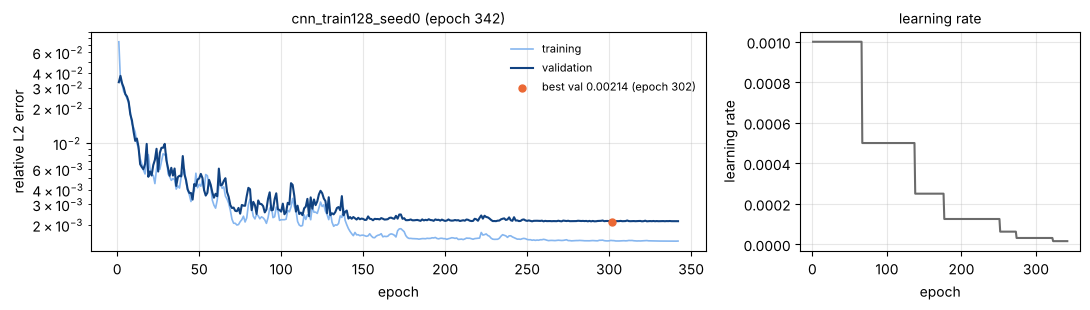

cnn_train128_seed0: 342 epochs in 90.6 s, best validation error 0.00214


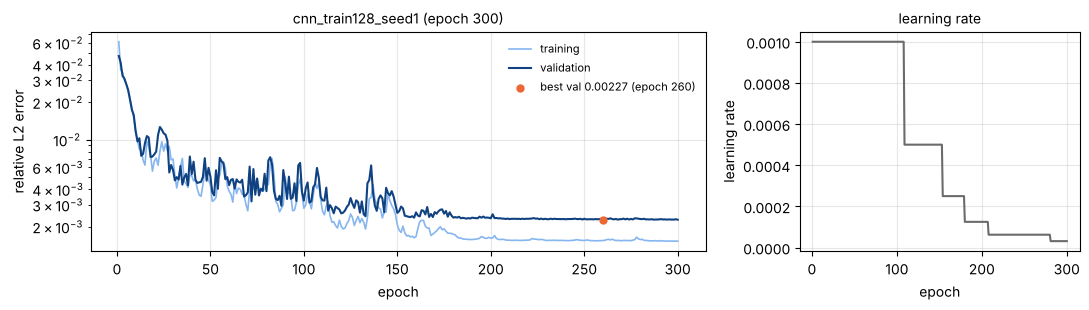

cnn_train128_seed1: 300 epochs in 74.5 s, best validation error 0.00227


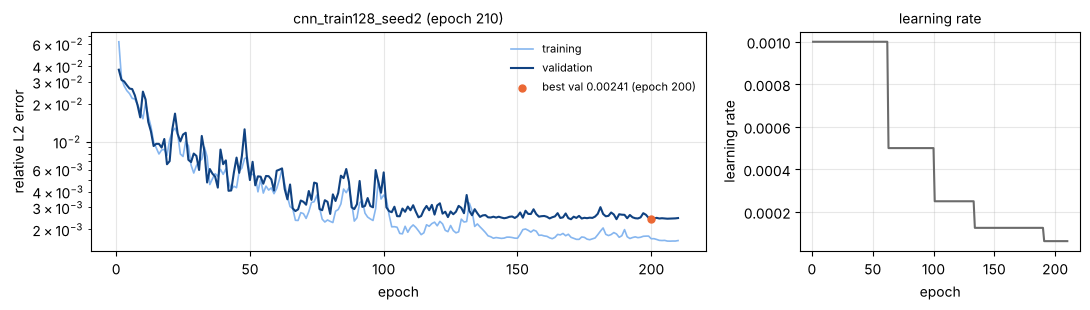

cnn_train128_seed2: 210 epochs in 50.3 s, best validation error 0.00241


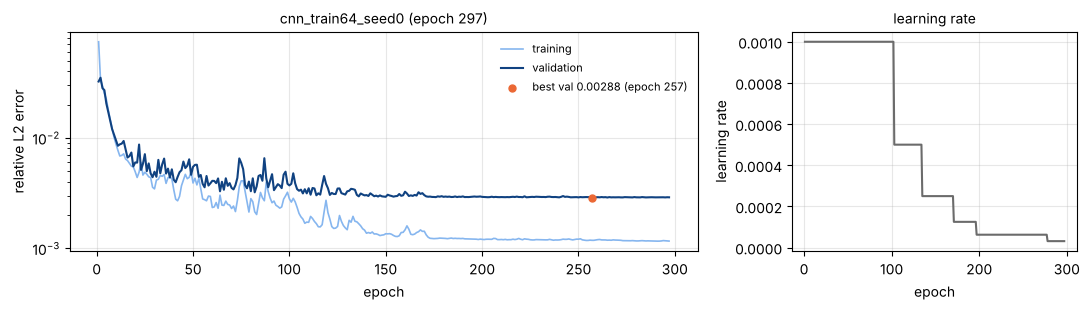

cnn_train64_seed0: 297 epochs in 51.1 s, best validation error 0.00288


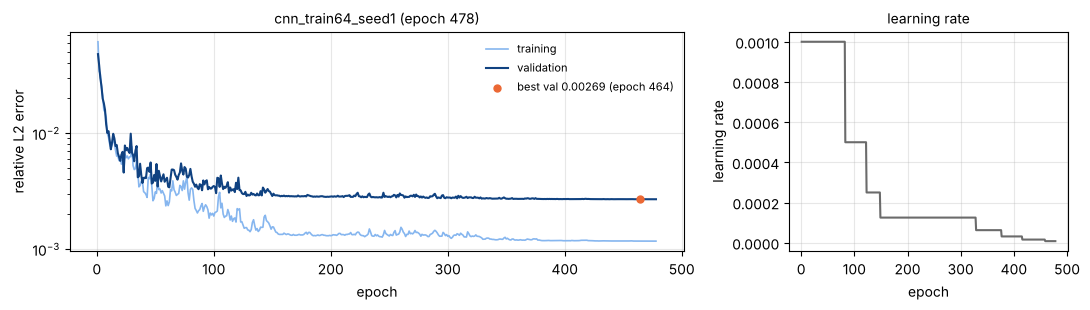

cnn_train64_seed1: 478 epochs in 77.2 s, best validation error 0.00269


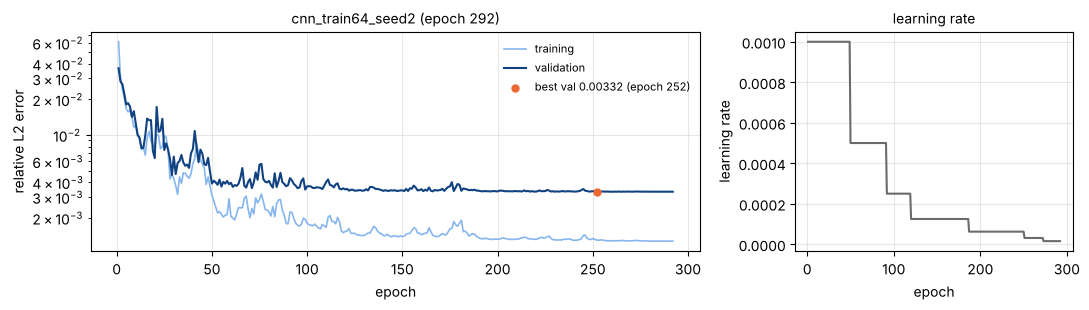

cnn_train64_seed2: 292 epochs in 49.3 s, best validation error 0.00332


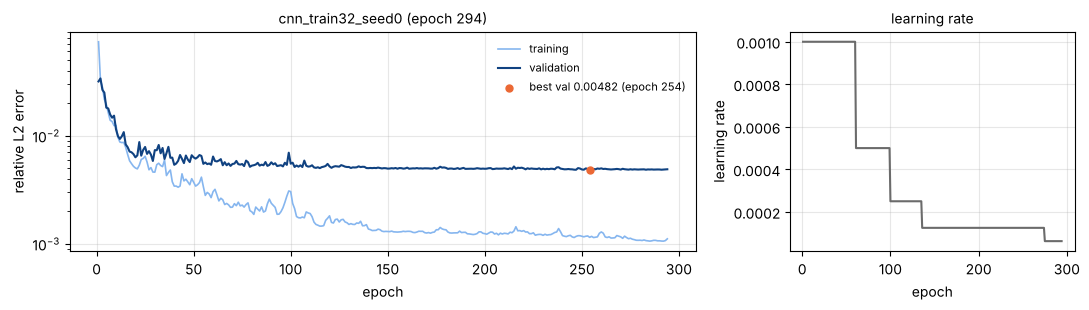

cnn_train32_seed0: 294 epochs in 39.3 s, best validation error 0.00482


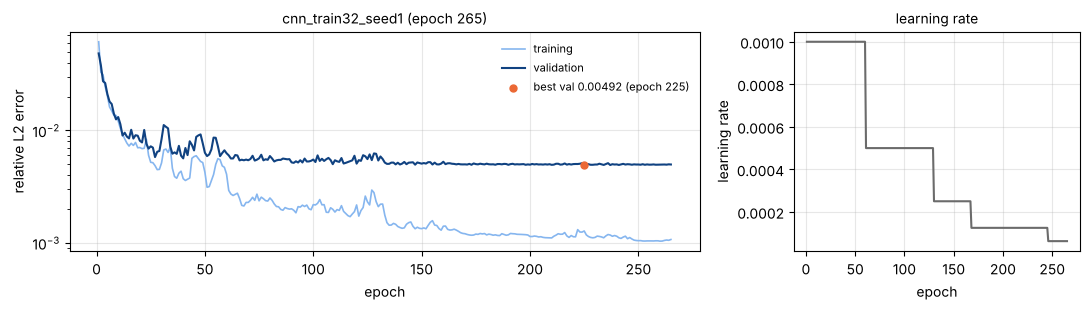

cnn_train32_seed1: 265 epochs in 33.9 s, best validation error 0.00492


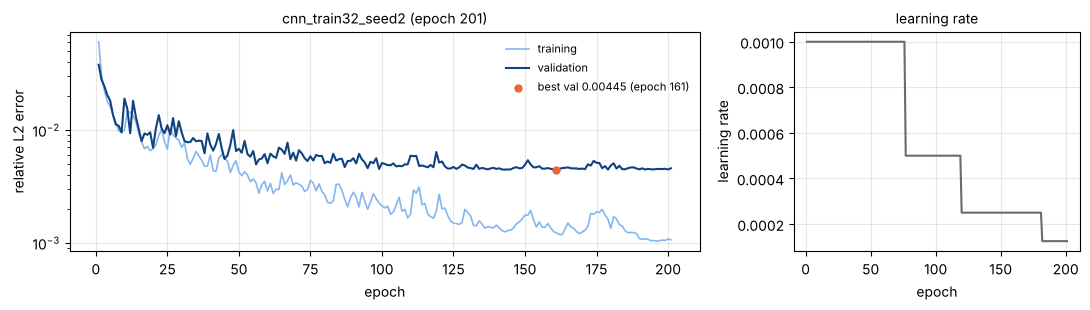

cnn_train32_seed2: 201 epochs in 25.6 s, best validation error 0.00445


In [8]:
for n_train in TRAIN_GRIDS:
    X, Y = load_train(n_train)
    for seed in SEEDS:
        tag = f"{MODEL}_train{n_train}_seed{seed}"
        path = os.path.join(CKPT, tag + ".pt")
        if SKIP_EXISTING and os.path.exists(path):
            ck = torch.load(path, map_location="cpu", weights_only=False)
            print(f"skip {tag}: checkpoint exists (best val {ck['info']['best_val']:.5f})")
            if ck.get("history"):                          # show its saved curve
                fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw=dict(width_ratios=[2.2, 1]))
                draw_curves(axes, ck["history"], f"{tag} (saved)"); plt.tight_layout(); plt.show()
            continue

        t0 = time.time()
        model, info, hist = train_cnn(X, Y, tr, va, seed, HP, monitor=LiveMonitor(tag))
        config = dict(hidden=HP["hidden"], kernel_size=HP["kernel_size"], num_layers=HP["num_layers"])
        info.update(model=MODEL, n_train=n_train, seed=seed, config=config, hyperparameters=HP,
                    seconds=round(time.time() - t0, 1))
        torch.save({"state": model.state_dict(), "config": config, "info": info, "history": hist}, path)
        with open(os.path.join(CKPT, tag + ".json"), "w") as f:
            json.dump(info, f, indent=1)
        print(f"{tag}: {info['epochs']} epochs in {info['seconds']} s, best validation error {info['best_val']:.5f}")

## 7. Overview: convergence of every CNN run

All saved runs side by side: one panel per training grid, one line per seed (solid = validation, faint = training).
What to check:
- **Seeds overlap:** the result does not depend on the random initialisation.
- **No validation curve turns upward at the end:** no overfitting.
- **Finer training grids reach lower error.** A 32-point grid sees less detail, so its error floor is higher.

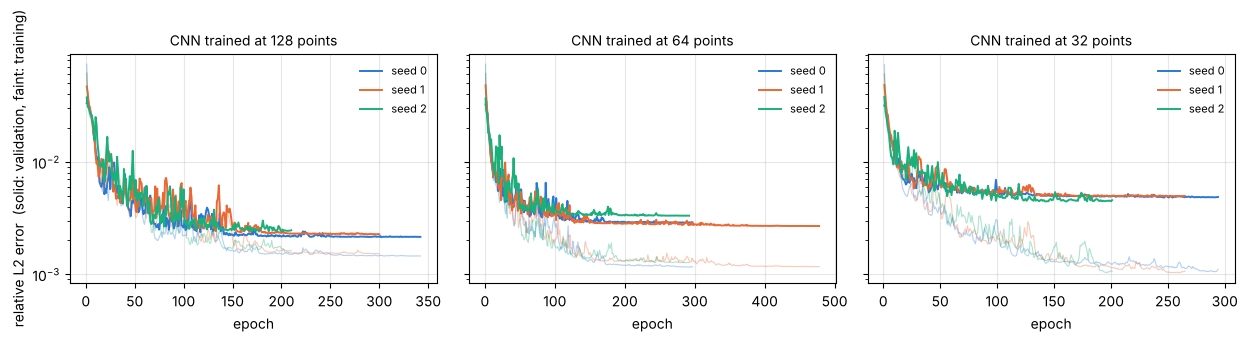

,grid,seed,best_val,best_epoch,epochs_run,seconds
0,128,0,0.002140,302,342,90.6
1,128,1,0.002270,260,300,74.5
2,128,2,0.002413,200,210,50.3
3,64,0,0.002878,257,297,51.1
4,64,1,0.002690,464,478,77.2
5,64,2,0.003320,252,292,49.3
6,32,0,0.004823,254,294,39.3
7,32,1,0.004918,225,265,33.9
8,32,2,0.004447,161,201,25.6


In [9]:
SEED_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]     # seed 0, 1, 2
grids = [n for n in (128, 64, 32) if any(os.path.exists(os.path.join(CKPT, f"{MODEL}_train{n}_seed{s}.pt")) for s in range(3))]
fig, axes = plt.subplots(1, len(grids), figsize=(4.2 * len(grids), 3.3), squeeze=False, sharey=True)
rows = []
for ax, n in zip(axes[0], grids):
    for s in range(3):
        path = os.path.join(CKPT, f"{MODEL}_train{n}_seed{s}.pt")
        if not os.path.exists(path):
            continue
        ck = torch.load(path, map_location="cpu", weights_only=False)
        h = ck.get("history")
        if h is None:
            continue
        ep = np.arange(1, len(h["val"]) + 1)
        ax.plot(ep, h["train"], color=SEED_COLORS[s], lw=0.8, alpha=0.35)
        ax.plot(ep, h["val"], color=SEED_COLORS[s], lw=1.4, label=f"seed {s}")
        rows.append(dict(grid=n, seed=s, best_val=ck["info"]["best_val"],
                         best_epoch=int(np.argmin(h["val"])) + 1, epochs_run=len(h["val"]),
                         seconds=ck["info"]["seconds"]))
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title(f"{MODEL.upper()} trained at {n} points", fontsize=10)
    ax.grid(alpha=0.3); ax.legend(fontsize=8, frameon=False)
axes[0][0].set_ylabel("relative L2 error  (solid: validation, faint: training)")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))

## 8. Sandbox: try other hyperparameters without touching the saved models

`try_cnn(...)` trains **one** CNN with some settings changed, draws its live curve **on top of the saved model's
validation curve** (grey), and does **not** save anything. Use it to see whether a change helps before you retrain
for real.

Example (uncomment to run, about 30 seconds):
```python
try_cnn(n_train=128, seed=0, lr=3e-4)                     # a smaller learning rate
try_cnn(n_train=128, seed=0, kernel_size=5, num_layers=6) # a bigger network
```
Important: choose hyperparameters by **validation** error only, never by the 256/512-point test results.
Otherwise the test is no longer a fair test.

In [10]:
def try_cnn(n_train=128, seed=0, **changes):
    hp = {**HP, **changes}                                 # the current settings with your changes
    X, Y = load_train(n_train)
    saved = os.path.join(CKPT, f"{MODEL}_train{n_train}_seed{seed}.pt")
    baseline = torch.load(saved, weights_only=False).get("history") if os.path.exists(saved) else None
    title = f"sandbox: CNN at {n_train} pts, seed {seed}, " + ", ".join(f"{k}={v}" for k, v in changes.items())
    model, info, hist = train_cnn(X, Y, tr, va, seed, hp, monitor=LiveMonitor(title, baseline))
    msg = f"best validation error {info['best_val']:.5f} after {info['epochs']} epochs"
    if baseline:
        msg += f"  (saved model: {min(baseline['val']):.5f})"
    print(msg)
    return model

# try_cnn(n_train=128, seed=0, lr=3e-4)